# Spacing between boreholes

Boreholes interfere less as they move apart, but spacing costs land. This notebook keeps the twelve
boreholes of `demo_project.py` on a 4 × 3 grid, varies their spacing from 3 to 12 m, and plots the
coldest entering fluid temperature of a 25-year simulation and the length the Sizing tool asks for.
It is the notebook version of `borehole_spacing.py`.

Run it from the `examples` folder, with the executable and a licence (see
[Installation](../docs/install.md)).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pyghe as ga
import ghestyle as ghe
from demo_project import make_project

ghe.use()

## One field per spacing, simulated and sized

In [2]:
spacings = np.arange(3.0, 12.1, 1.0)                 # m

p = make_project()
variants = []
for spacing in spacings:
    q = p.copy()
    q.ground_heat_exchanger.coordinates = ga.Coordinates.rectangle(nx=4, ny=3, spacing=spacing)
    variants.append(q)

coldest = [r.summary.minimum_eft for r in ga.run_many(variants, "simulate")]
lengths = [r.governing_total_borehole_length for r in ga.run_many(variants, "size")]

for spacing, temperature, length in zip(spacings, coldest, lengths):
    print(f"B = {spacing:4.1f} m  ->  minimum EFT {temperature:5.2f} °C, L = {length:5.0f} m")

B =  3.0 m  ->  minimum EFT -1.16 °C, L =  1204 m
B =  4.0 m  ->  minimum EFT -0.23 °C, L =  1113 m
B =  5.0 m  ->  minimum EFT  0.26 °C, L =  1055 m
B =  6.0 m  ->  minimum EFT  0.59 °C, L =  1013 m
B =  7.0 m  ->  minimum EFT  0.84 °C, L =   981 m
B =  8.0 m  ->  minimum EFT  1.04 °C, L =   956 m
B =  9.0 m  ->  minimum EFT  1.22 °C, L =   934 m
B = 10.0 m  ->  minimum EFT  1.38 °C, L =   917 m
B = 11.0 m  ->  minimum EFT  1.52 °C, L =   902 m
B = 12.0 m  ->  minimum EFT  1.64 °C, L =   889 m


## Figure

Both curves flatten as the spacing grows. The first metres of spacing gain the most.

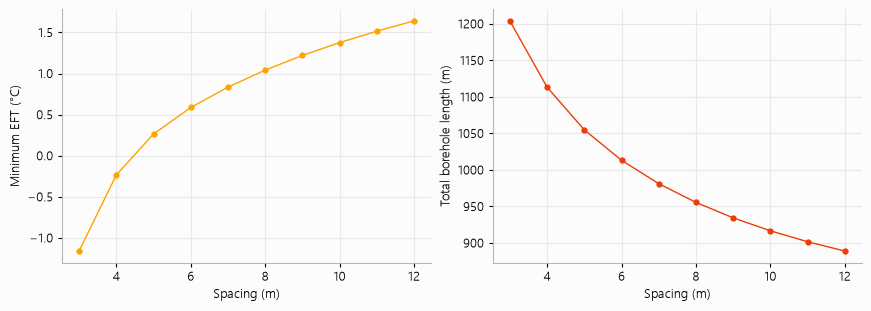

In [3]:
fig, (left, right) = plt.subplots(1, 2, figsize=(8.6, 3.0))
left.plot(spacings, coldest, color=ghe.ORANGE, marker="o", markersize=3.5)
ghe.axis_titles(left, "Spacing (m)", "Minimum EFT (°C)")
right.plot(spacings, lengths, color=ghe.HEATING, marker="o", markersize=3.5)
ghe.axis_titles(right, "Spacing (m)", "Total borehole length (m)")
plt.show()